### Libraries

In [1]:
import os
import glob
import nibabel as nb
import scipy.stats
from brainspace.mesh.mesh_io import read_surface
from brainspace.plotting import plot_hemispheres
from brainspace.gradient import GradientMaps
from brainspace.mesh.array_operations import smooth_array
import numpy as np
import seaborn as sns
import pandas as pd
import cmocean
import matplotlib.pyplot as plt
import matplotlib as mpl
from brainspace.datasets import load_mask
from matplotlib.lines import Line2D
import colormaps as clrmps
import matplotlib.cm as cm
from cmcrameri import cm

### Variables

In [2]:
# Set dataset PNI as working directory
os.chdir('/data_/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0')

# Path to MICAPIPEsurf = mask_5k !
micapipe=os.popen("echo $MICAPIPE").read()[:-1]

# Load native mid surface
inf_lh = read_surface(micapipe + '/surfaces/fsLR-5k.L.inflated.surf.gii', itype='gii')
inf_rh = read_surface(micapipe + '/surfaces/fsLR-5k.R.inflated.surf.gii', itype='gii')

mask_lh =  nb.load(micapipe + '/surfaces/fsLR-5k.R.mask.shape.gii').darrays[0].data
mask_rh =  nb.load(micapipe + '/surfaces/fsLR-5k.L.mask.shape.gii').darrays[0].data
mask_5k = np.concatenate((mask_lh, mask_rh), axis=0)

# Load fsLR 5k
f5k_lh = read_surface(micapipe + '/surfaces/fsLR-5k.L.surf.gii', itype='gii')
f5k_rh = read_surface(micapipe + '/surfaces/fsLR-5k.R.surf.gii', itype='gii')

# Load fsLR 32k
f32k_lh = read_surface(micapipe + '/surfaces/fsLR-32k.L.surf.gii', itype='gii')
f32k_rh = read_surface(micapipe + '/surfaces/fsLR-32k.R.surf.gii', itype='gii')
# Load fsLR 32k inflated
f32k_inf_lh = read_surface(micapipe + '/surfaces/fsLR-32k.L.inflated.surf.gii', itype='gii')
f32k_inf_rh = read_surface(micapipe + '/surfaces/fsLR-32k.R.inflated.surf.gii', itype='gii')
mask_32k = load_mask(join=True)

# Boolean mask
#mask_surf = mask_5k != 0
mask_surf = mask_32k != 0

### Functions

In [3]:
# Function: Smooth intensity profiles on a given surface
def smooth_surf(surf_l, surf_r, points, Mask, Kernel='uniform', Niter=3, Relax=0.35):
    '''
    Smooths intensity data on a given surface mesh using iterative smoothing.
    
    Parameters:
    -----------
    surf_l : np.array
        Left hemisphere surface connectivity.
    surf_r : np.array
        Right hemisphere surface connectivity.
    points : np.array
        Intensity profile data mapped to the surface.
    Mask : np.array
        Binary mask indicating valid regions for smoothing.
    Kernel : str, optional
        Smoothing kernel type, options: {'uniform', 'gaussian', 'inverse_distance'}.
    Niter : int, optional
        Number of smoothing iterations (default: 3).
    Relax : float, optional
        Relaxation factor controlling smoothing intensity (default: 0.35).
    
    Returns:
    --------
    sdata : np.array
        Smoothed intensity data.
    '''
    Ndim = Mask.shape[0] 
    n2dim = int(Ndim/2)
    Mask_l = Mask[:n2dim]
    Mask_r = Mask[n2dim:]
    
    sdata = np.concatenate((
        smooth_array(surf_l, points[:n2dim], kernel=Kernel, n_iter=Niter, relax=Relax, mask=Mask_l), 
        smooth_array(surf_r, points[n2dim:], kernel=Kernel, n_iter=Niter, relax=Relax, mask=Mask_r)
    ), axis=0)
    
    return sdata

# Function: Apply smoothing to intensity profiles across all depths
def smooth_intensities(int_profile):
    '''
    Applies surface smoothing to each depth of the intensity profile.
    
    Parameters:
    -----------
    int_profile : np.array
        Input intensity profiles, where rows represent different depths.
    
    Returns:
    --------
    smoothed_i : np.array
        Smoothed intensity profiles.
    '''
    smoothed_i = np.copy(int_profile)
    
    for i in range(int_profile.shape[0]):
        smoothed_i[i, :] = smooth_surf(
            f32k_inf_lh, f32k_inf_rh, int_profile[i, :], mask_surf, Niter=5, Relax=0.5, Kernel='uniform'
        )
    
    return smoothed_i

In [4]:
def fill_missing_Turkey(cdata):
    # Calculate the first and third quartiles
    Q1 = np.nanpercentile(cdata, 25)
    Q3 = np.nanpercentile(cdata, 75)

    # Calculate the interquartile range (IQR)
    IQR = Q3 - Q1

    # Define the outlier thresholds based on Tukey's method
    lower_threshold = Q1 - 1.5 * IQR
    upper_threshold = Q3 + 1.5 * IQR

    # Identify outliers based on Tukey's method
    outliers = (cdata < lower_threshold) | (cdata > upper_threshold)

    # Set outliers to NaN
    cdata[outliers] = np.nan

    # Interpolate NaNs
    good = np.where(~np.isnan(cdata))
    bad = np.where(np.isnan(cdata))
    fill = scipy.interpolate.griddata(good, cdata[good], bad)
    cdata[bad] = fill

    # Extrapolate any remaining missing values
    good = np.where(~np.isnan(cdata))
    bad = np.where(np.isnan(cdata))
    fill = scipy.interpolate.griddata(good, cdata[good], bad, method='nearest')
    cdata[bad] = fill
    
    return cdata

In [5]:
def load_par_matrix(subj_path):
    lh_path = os.path.join(subj_path, 'L_fsLR32k_afd-par.txt')
    rh_path = os.path.join(subj_path, 'R_fsLR32k_afd-par.txt')

    lh = np.loadtxt(lh_path)
    rh = np.loadtxt(rh_path)

    #depths = [0, 2, 4, 6]   # 0,1,2,3 mm
    depths = [0,1,2,3,4,5,6]

    mats = []
    for d in depths:
        tmp = np.concatenate((lh[:, d], rh[:, d]), axis=0)
        tmp[tmp == -1] = np.nan
        mats.append(tmp)

    return np.vstack(mats)      # (4, vertices)

def load_perp_matrix(subj_path):
    lh_path = os.path.join(subj_path, 'L_fsLR32k_afd-perp-av.txt')
    rh_path = os.path.join(subj_path, 'R_fsLR32k_afd-perp-av.txt')

    lh = np.loadtxt(lh_path)
    rh = np.loadtxt(rh_path)

    depths = [0, 2, 4, 6]   # 0,1,2,3 mm
    depths = [0,1,2,3,4,5,6]

    mats = []
    for d in depths:
        tmp = np.concatenate((lh[:, d], rh[:, d]), axis=0)
        tmp[tmp == -1] = np.nan
        mats.append(tmp)

    return np.vstack(mats)      # (4, vertices)

## AFD - parallel (long range fibres)

In [6]:
base_dir = '/host/verges/tank/data/youngeun/myproject/FBA/3T_7T/subjects_csd/'
subject_dirs = [
    'PNC003_HC082', 'PNC006_HC081', 'PNC011_HC083', 'PNC018_HC076',
    'PNC019_HC062', 'PNC022_HC132', 'PNC024_HC088', 'PNC025_HC128',
    'PNC026_HC130', 'PNC037_HC116', 'PNC038_HC140'
]

ses_dirs = ['03', '03', '03', '03', '03', '03', 'a1', 'a1', 'a1', 'a1', 'a1']

In [7]:
all_par_SWM = []

#for subj in subject_dirs:
for subj, ses in zip(subject_dirs, ses_dirs):

    # -------------------------------
    # load gyrus and sulcus
    # -------------------------------
    gyrus_path = os.path.join(base_dir, subj, "Gyrus_40")
    sulcus_path = os.path.join(base_dir, subj, "Sulcus_50")

    try:

        par_gyrus = load_par_matrix(gyrus_path)
        par_sulcus = load_par_matrix(sulcus_path)

        # -------------------------------
        # curvature
        # -------------------------------
        #ses = subj.split("_")[1]   

        cfile = glob.glob(
            f"/data/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0/"
            f"sub-{subj.split('_')[0]}/ses-{ses}/maps/"
            f"sub-{subj.split('_')[0]}_ses-{ses}_hemi-L_surf-fsLR-32k_label-curv.func.gii"
        )[0]

        cdata_l = nb.load(cfile).darrays[0].data

        cfile = glob.glob(
            f"/data/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0/"
            f"sub-{subj.split('_')[0]}/ses-{ses}/maps/"
            f"sub-{subj.split('_')[0]}_ses-{ses}_hemi-R_surf-fsLR-32k_label-curv.func.gii"
        )[0]

        cdata_r = nb.load(cfile).darrays[0].data

        curvature = np.concatenate([cdata_l, cdata_r])

        # -------------------------------
        # curvature mask
        # positive = gyrus
        # negative = sulcus
        # -------------------------------
        gyrus_mask = curvature > 0
        sulcus_mask = curvature <= 0

        # -------------------------------
        # merge
        # -------------------------------
        par_SWM = np.empty_like(par_gyrus)

        for d in range(par_gyrus.shape[0]):

            merged = np.empty_like(par_gyrus[d])

            merged[gyrus_mask] = par_gyrus[d, gyrus_mask]
            merged[sulcus_mask] = par_sulcus[d, sulcus_mask]

            par_SWM[d] = merged

        # -------------------------------
        # fill missing
        # -------------------------------
        filled = np.empty_like(par_SWM)

        for i in range(par_SWM.shape[0]):
            filled[i] = fill_missing_Turkey(par_SWM[i])

        par_smooth = smooth_intensities(filled)

        all_par_SWM.append(par_smooth)

    except Exception as e:
        print(subj, e)

all_par_SWM = np.stack(all_par_SWM, axis=0)
mean_par_SWM = np.nanmean(all_par_SWM, axis=0)

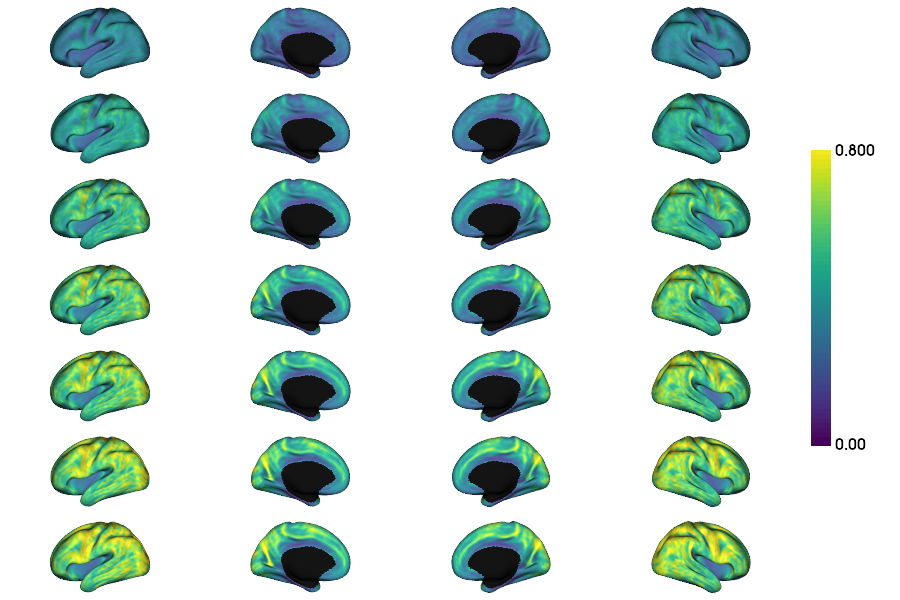

In [8]:
mean_par_SWM[:,mask_32k == False] = np.nan
plot_hemispheres(f32k_inf_lh, f32k_inf_rh, array_name=mean_par_SWM, size=(900, 600), color_bar='right', zoom=1.5, embed_nb=True, interactive=False, share='both', nan_color=(0, 0, 0, 1), 
                 cmap='viridis', transparent_bg=True, screenshot=False, color_range=(0,0.8))

In [9]:
np.save('/host/verges/tank/data/youngeun/myjupyter/array/AFD_par_allsubs_7surf.npy', all_par_SWM)
np.save('/host/verges/tank/data/youngeun/myjupyter/array/AFD_par_average_7surf.npy', mean_par_SWM)

## AFD - perpendicular-average (u-fibers)

In [10]:
all_perpav_SWM = []

#for subj in subject_dirs:
for subj, ses in zip(subject_dirs, ses_dirs):

    # -------------------------------
    # load gyrus and sulcus
    # -------------------------------
    gyrus_path = os.path.join(base_dir, subj, "Gyrus_40")
    sulcus_path = os.path.join(base_dir, subj, "Sulcus_50")

    try:

        perp_gyrus = load_perp_matrix(gyrus_path)
        perp_sulcus = load_perp_matrix(sulcus_path)

        # -------------------------------
        # curvature
        # -------------------------------
        #ses = subj.split("_")[1]   

        cfile = glob.glob(
            f"/data/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0/"
            f"sub-{subj.split('_')[0]}/ses-{ses}/maps/"
            f"sub-{subj.split('_')[0]}_ses-{ses}_hemi-L_surf-fsLR-32k_label-curv.func.gii"
        )[0]

        cdata_l = nb.load(cfile).darrays[0].data

        cfile = glob.glob(
            f"/data/mica3/BIDS_PNI/derivatives/micapipe_v0.2.0/"
            f"sub-{subj.split('_')[0]}/ses-{ses}/maps/"
            f"sub-{subj.split('_')[0]}_ses-{ses}_hemi-R_surf-fsLR-32k_label-curv.func.gii"
        )[0]

        cdata_r = nb.load(cfile).darrays[0].data

        curvature = np.concatenate([cdata_l, cdata_r])

        # -------------------------------
        # curvature mask
        # positive = gyrus
        # negative = sulcus
        # -------------------------------
        gyrus_mask = curvature > 0
        sulcus_mask = curvature <= 0

        # -------------------------------
        # merge
        # -------------------------------
        perp_SWM = np.empty_like(perp_gyrus)

        for d in range(perp_gyrus.shape[0]):

            merged = np.empty_like(perp_gyrus[d])

            merged[gyrus_mask] = perp_gyrus[d, gyrus_mask]
            merged[sulcus_mask] = perp_sulcus[d, sulcus_mask]

            perp_SWM[d] = merged

        # -------------------------------
        # fill missing
        # -------------------------------
        filled = np.empty_like(perp_SWM)

        for i in range(perp_SWM.shape[0]):
            filled[i] = fill_missing_Turkey(perp_SWM[i])

        perp_smooth = smooth_intensities(filled)

        all_perpav_SWM.append(perp_smooth)

    except Exception as e:
        print(subj, e)

all_perpav_SWM = np.stack(all_perpav_SWM, axis=0)
mean_perpav_SWM = np.nanmean(all_perpav_SWM, axis=0)

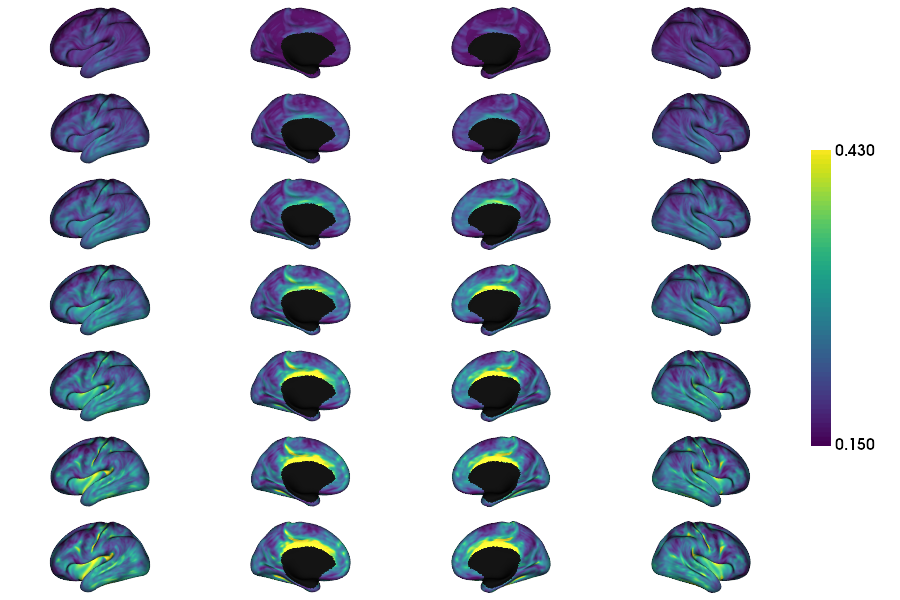

In [11]:
mean_perpav_SWM[:,mask_32k == False] = np.nan
plot_hemispheres(f32k_inf_lh, f32k_inf_rh, array_name=mean_perpav_SWM, size=(900, 600), color_bar='right', zoom=1.5, embed_nb=True, interactive=False, share='both', nan_color=(0, 0, 0, 1), 
                 cmap='viridis', transparent_bg=True, screenshot=False, color_range=(0.15,0.43))

In [12]:
np.save('/host/verges/tank/data/youngeun/myjupyter/array/AFD_perpav_allsubs_7surf.npy', all_perpav_SWM)
np.save('/host/verges/tank/data/youngeun/myjupyter/array/AFD_perpav_average_7surf.npy', mean_perpav_SWM)